# Аналитика продаж DonorSearch Shop на маркетплейсах (Яндекс Маркет и Ozon)
## Аналитический отчет и система поддержки принятия решений

**Цель исследования:** аудит коммерческой эффективности каналов продаж, расчет юнит-экономики, оценка конверсий воронки и формирование приоритизированного реестра действий по ассортименту.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display

# Добавляем корень проекта для загрузки конфигурации и модулей
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import PROCESSED_DIR, INTERIM_DIR, OUTPUT_DIR, COMMON_WINDOW_START, COMMON_WINDOW_END
from src.market import find_col, num

# Настройки графиков
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False
})
PALETTE = ['#20808D', '#A84B2F', '#1B474D', '#944454']

def rub(x): return f"{x:,.0f}".replace(',', ' ')
def pct(x): return '—' if pd.isna(x) else f"{x:.1f}%"
def show(df, n=15):
    display(df.head(n).style.format(precision=1, thousands=' ', decimal=',', na_rep='—'))

# Загрузка аналитических витрин и кэшей
mart_sku = pd.read_parquet(PROCESSED_DIR / 'mart_sku_month.parquet')
mart_platform = pd.read_parquet(PROCESSED_DIR / 'mart_platform_month.parquet')
mart_summary = pd.read_parquet(PROCESSED_DIR / 'mart_sku_summary.parquet')
ym_raw = pd.read_parquet(INTERIM_DIR / 'ym_raw.parquet')
funnel = pd.read_parquet(INTERIM_DIR / 'funnel_raw.parquet')
recommendations = pd.read_csv(OUTPUT_DIR / 'sku_recommendations.csv', sep=';')

print(f"Витрина mart_sku_month: {len(mart_sku):,} строк")
print(f"Реестр рекомендаций: {len(recommendations):,} SKU")

Витрина mart_sku_month: 1,241 строк
Реестр рекомендаций: 122 SKU


### 1. Сводные финансовые показатели за весь период

In [2]:
platform_tot = mart_sku.groupby('площадка', as_index=False).agg(
    выручка=('выручка', 'sum'),
    прибыль=('прибыль', 'sum'),
    себестоимость=('себестоимость_итого', 'sum'),
    расходы_площадки=('расходы_площадки', 'sum'),
    количество=('количество', 'sum')
)
platform_tot['маржа_%'] = platform_tot['прибыль'] / platform_tot['выручка'] * 100
platform_tot['средний_чек_руб'] = platform_tot['выручка'] / platform_tot['количество']
show(platform_tot)

,площадка,выручка,прибыль,себестоимость,расходы_площадки,количество,маржа_%,средний_чек_руб
0,Ozon,"574 829,8","218 690,1","251 506,0","104 633,7",1 115,"38,0","515,5"
1,Яндекс Маркет,"1 936 343,0","855 922,8","1 005 254,0","75 166,2",2 988,"44,2","648,0"


### 2. Динамика помесячной выручки (График 1: Маркет и Ozon)

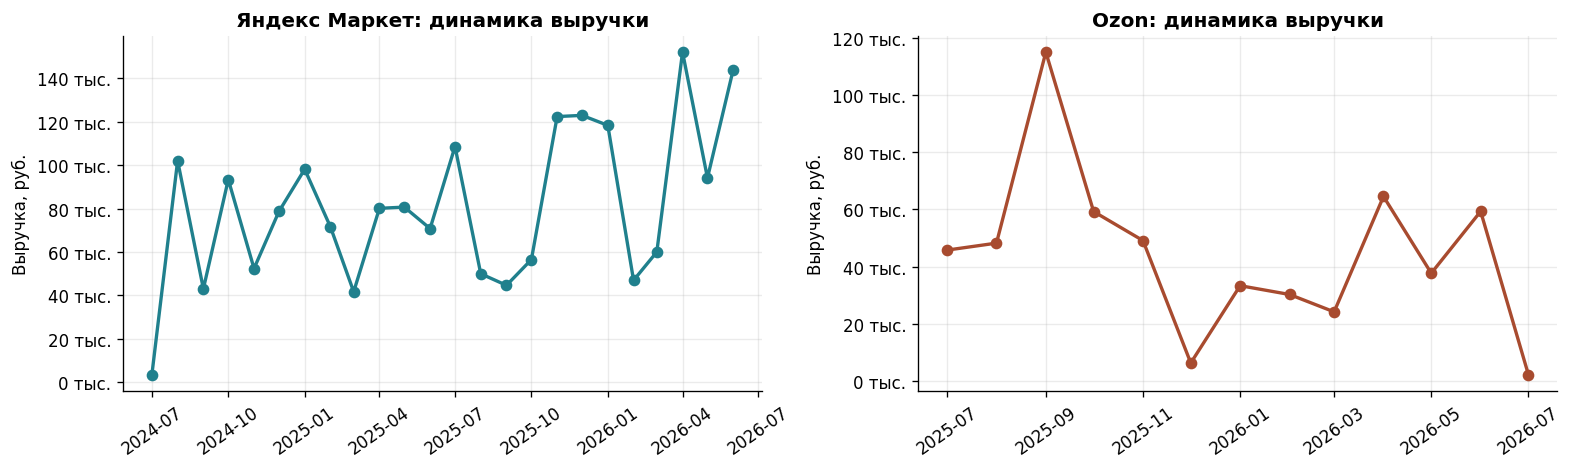

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), layout='constrained')
for ax, (platform, color) in zip(axes, [('Яндекс Маркет', PALETTE[0]), ('Ozon', PALETTE[1])]):
    df_p = mart_platform[mart_platform['площадка'] == platform].sort_values('период')
    ax.plot(df_p['период'], df_p['выручка'], marker='o', color=color, lw=2)
    ax.set_title(f'{platform}: динамика выручки')
    ax.set_ylabel('Выручка, руб.')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x/1000:.0f} тыс.'))
    ax.grid(alpha=0.25)
    ax.tick_params(axis='x', rotation=35)
plt.show()

### 3. Сравнение на общем периоде и динамика среднего чека (График 2: Средний чек)

,площадка,выручка,прибыль,себестоимость,расходы_площадки,количество,маржа_%,средний_чек_руб
0,Ozon,"572 753,8","217 623,0","251 009,0","104 121,8",1 111,"38,0","515,5"
1,Яндекс Маркет,"1 120 529,0","474 057,2","611 501,0","34 970,8",1 867,"42,3","600,2"


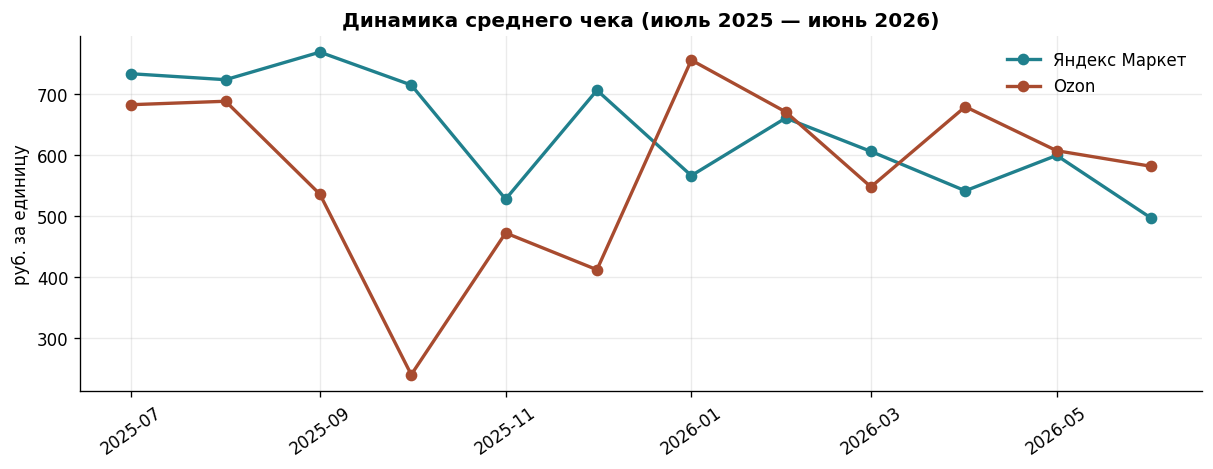

In [4]:
shared = mart_sku[
    (mart_sku['период'] >= pd.Timestamp(COMMON_WINDOW_START)) &
    (mart_sku['период'] <= pd.Timestamp(COMMON_WINDOW_END)) &
    (mart_sku['полный_месяц'])
].copy()

compare = shared.groupby('площадка', as_index=False).agg(
    выручка=('выручка', 'sum'),
    прибыль=('прибыль', 'sum'),
    себестоимость=('себестоимость_итого', 'sum'),
    расходы_площадки=('расходы_площадки', 'sum'),
    количество=('количество', 'sum')
)
compare['маржа_%'] = compare['прибыль'] / compare['выручка'] * 100
compare['средний_чек_руб'] = compare['выручка'] / compare['количество']
show(compare)

# График 2: Динамика среднего чека
avg_check_m = shared.groupby(['период', 'площадка'], as_index=False).agg(
    выручка=('выручка', 'sum'),
    количество=('количество', 'sum')
)
avg_check_m['средний_чек_руб'] = avg_check_m['выручка'] / avg_check_m['количество']

fig, ax = plt.subplots(figsize=(10, 3.8), layout='constrained')
for platform, color in [('Яндекс Маркет', PALETTE[0]), ('Ozon', PALETTE[1])]:
    sub = avg_check_m[avg_check_m['площадка'] == platform].sort_values('период')
    ax.plot(sub['период'], sub['средний_чек_руб'], marker='o', lw=2, label=platform, color=color)
ax.set_title('Динамика среднего чека (июль 2025 — июнь 2026)')
ax.set_ylabel('руб. за единицу')
ax.legend(frameon=False)
ax.grid(alpha=0.25)
ax.tick_params(axis='x', rotation=35)
plt.show()

### 4. Анализ скидок и разрыва цен (Графики 3 и 4: Скидки Маркета и Ozon)

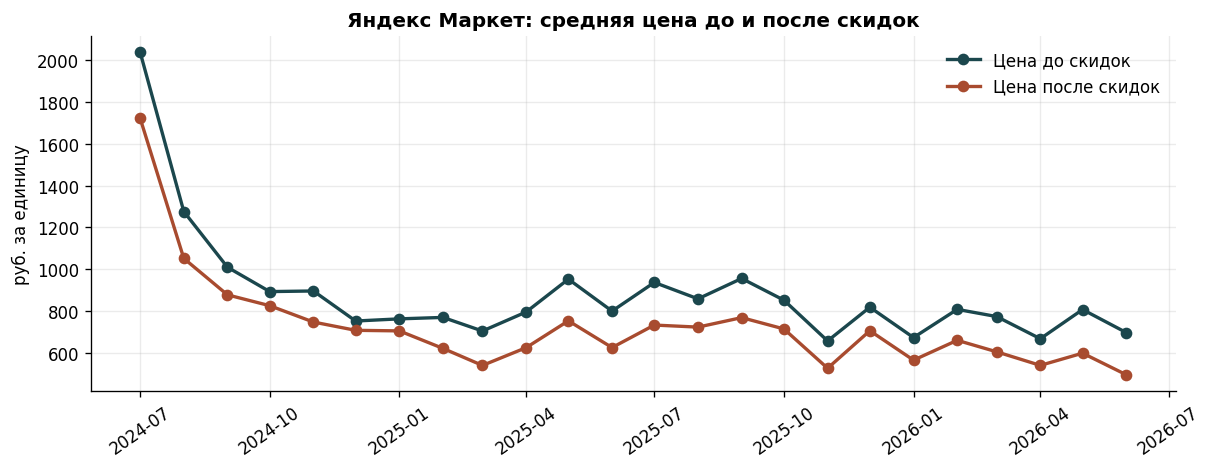

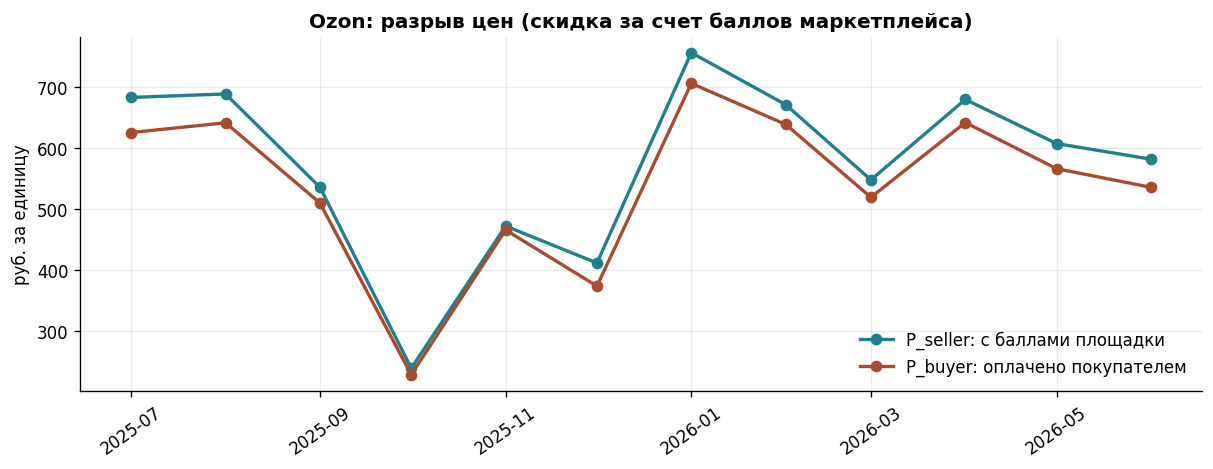

In [5]:
# График 3: Скидки Маркета (цена до vs после скидок)
pre_col = find_col(ym_raw, ['Цена c НДС без учёта скидок за шт., ₽'], required=False)
post_col = find_col(ym_raw, ['Цена с НДС с учётом всех скидок за шт., ₽'], required=False)
qty_col = find_col(ym_raw, ['Доставлено, шт.'], required=False)
dt_col = find_col(ym_raw, ['Дата доставки товара', 'Дата оформления заказа'], required=False)

if pre_col and post_col:
    disc_df = ym_raw.copy()
    disc_df['период'] = pd.to_datetime(disc_df[dt_col], errors='coerce', dayfirst=True).dt.to_period('M').dt.to_timestamp()
    disc_df['qty'] = num(disc_df[qty_col])
    disc_df['pre'] = num(disc_df[pre_col]) * disc_df['qty']
    disc_df['post'] = num(disc_df[post_col]) * disc_df['qty']

    m_price = disc_df.groupby('период', as_index=False).agg(qty=('qty', 'sum'), pre=('pre', 'sum'), post=('post', 'sum'))
    m_price = m_price[m_price['qty'] > 0].sort_values('период')
    m_price['до_скидки'] = m_price['pre'] / m_price['qty']
    m_price['после_скидки'] = m_price['post'] / m_price['qty']

    fig, ax = plt.subplots(figsize=(10, 3.8), layout='constrained')
    ax.plot(m_price['период'], m_price['до_скидки'], marker='o', label='Цена до скидок', color=PALETTE[2], lw=2)
    ax.plot(m_price['период'], m_price['после_скидки'], marker='o', label='Цена после скидок', color=PALETTE[1], lw=2)
    ax.set_title('Яндекс Маркет: средняя цена до и после скидок')
    ax.set_ylabel('руб. за единицу')
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    ax.tick_params(axis='x', rotation=35)
    plt.show()

# График 4: Разрыв цен Ozon (P_seller vs P_buyer)
oz_price_source = mart_sku[(mart_sku['площадка'] == 'Ozon') & (mart_sku['полный_месяц']) & (mart_sku['количество'] > 0)].copy()
oz_price = oz_price_source.groupby('период', as_index=False).agg(
    количество=('количество', 'sum'),
    выручка_покупатель=('выручка_покупатель', 'sum'),
    выручка=('выручка', 'sum')
)
oz_price['P_buyer'] = oz_price['выручка_покупатель'] / oz_price['количество']
oz_price['P_seller'] = oz_price['выручка'] / oz_price['количество']

fig, ax = plt.subplots(figsize=(10, 3.8), layout='constrained')
ax.plot(oz_price['период'], oz_price['P_seller'], marker='o', label='P_seller: с баллами площадки', color=PALETTE[0], lw=2)
ax.plot(oz_price['период'], oz_price['P_buyer'], marker='o', label='P_buyer: оплачено покупателем', color=PALETTE[1], lw=2)
ax.set_title('Ozon: разрыв цен (скидка за счет баллов маркетплейса)')
ax.set_ylabel('руб. за единицу')
ax.legend(frameon=False)
ax.grid(alpha=0.25)
ax.tick_params(axis='x', rotation=35)
plt.show()

### 5. Кейс термостаканов: риск ликвидации ниже себестоимости (График 5: Бар-чарт)

,Площадка,Артикул,Период,Количество,Цена покупателя,Себестоимость
0,Яндекс Маркет,термо_красный,11.2024,12,"45,9","780,0"
1,Ozon,термо_ДС,09.2025,8,"146,4","780,0"


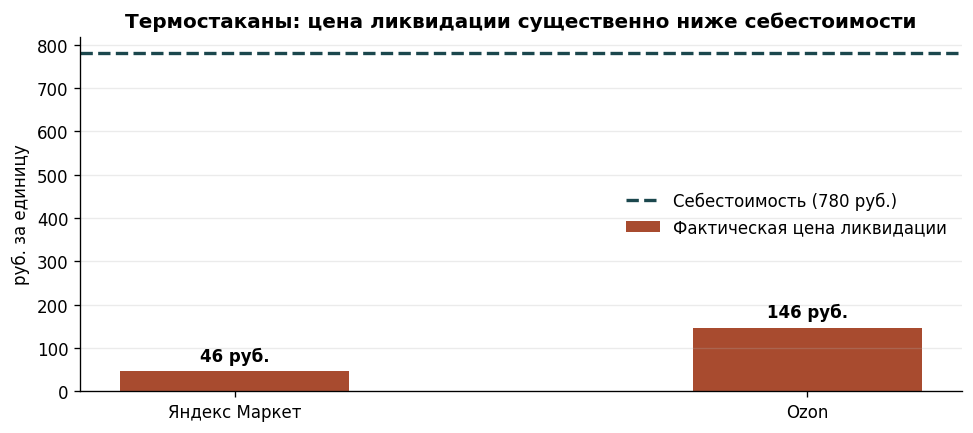

In [6]:
# Анализ ликвидационных продаж термостаканов (себестоимость 780 руб.)
thermo_cases = pd.DataFrame([
    {'Площадка': 'Яндекс Маркет', 'Артикул': 'термо_красный', 'Период': '11.2024', 'Количество': 12, 'Цена покупателя': 45.9, 'Себестоимость': 780.0},
    {'Площадка': 'Ozon', 'Артикул': 'термо_ДС', 'Период': '09.2025', 'Количество': 8, 'Цена покупателя': 146.4, 'Себестоимость': 780.0}
])
show(thermo_cases)

# График 5: Сравнение цены продажи с себестоимостью
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
bars = ax.bar(thermo_cases['Площадка'], thermo_cases['Цена покупателя'], color=PALETTE[1], width=0.4, label='Фактическая цена ликвидации')
ax.axhline(780, color=PALETTE[2], ls='--', lw=2, label='Себестоимость (780 руб.)')
ax.set_title('Термостаканы: цена ликвидации существенно ниже себестоимости')
ax.set_ylabel('руб. за единицу')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.25)
for b, val in zip(bars, thermo_cases['Цена покупателя']):
    ax.text(b.get_x() + b.get_width() / 2, val + 25, f"{val:.0f} руб.", ha='center', fontweight='bold')
plt.show()

### 6. Воронка конверсий Яндекс Маркета (График 6: Горизонтальная воронка)

,Этап,Количество,"Конверсия от предыдущего, %"
0,Показы,"1 825 119,0","100,0"
1,Корзины,"9 349,0","0,5"
2,Заказано,"2 493,0","26,7"
3,Доставлено / выкуплено,"2 988,0","119,9"


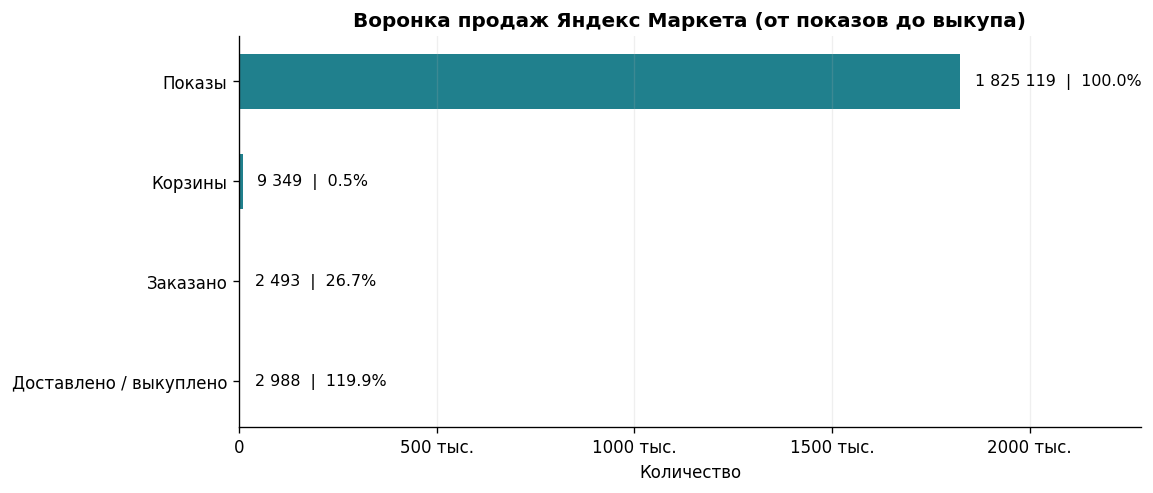

In [7]:
f_imp = float(num(funnel[find_col(funnel, ['Показы моих товаров, шт.'])]).sum())
f_cart = float(num(funnel[find_col(funnel, ['Добавления в корзину, шт.'])]).sum())
f_order = float(num(funnel[find_col(funnel, ['Заказанные товары, шт.'])]).sum())
f_deliv = float(num(ym_raw[find_col(ym_raw, ['Доставлено, шт.'])]).sum())

funnel_data = pd.DataFrame([
    ('Показы', f_imp),
    ('Корзины', f_cart),
    ('Заказано', f_order),
    ('Доставлено / выкуплено', f_deliv)
], columns=['Этап', 'Количество'])

funnel_data['Конверсия от предыдущего, %'] = [100.0, f_cart / f_imp * 100, f_order / f_cart * 100, f_deliv / f_order * 100]
show(funnel_data)

# График 6: Горизонтальный Bar-Chart воронки
fig, ax = plt.subplots(figsize=(9.5, 4), layout='constrained')
bars = ax.barh(funnel_data['Этап'], funnel_data['Количество'], color=PALETTE[0], height=0.55)
ax.invert_yaxis()
ax.set_xlim(0, funnel_data['Количество'].max() * 1.25)
ax.set_title('Воронка продаж Яндекс Маркета (от показов до выкупа)')
ax.set_xlabel('Количество')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x/1000:.0f} тыс.' if x >= 1000 else f'{x:.0f}'))
ax.grid(axis='x', alpha=0.2)

for b, (_, r) in zip(bars, funnel_data.iterrows()):
    w = b.get_width()
    ax.text(w + funnel_data['Количество'].max() * 0.02, b.get_y() + b.get_height() / 2,
            f"{rub(w)}  |  {r['Конверсия от предыдущего, %']:.1f}%", va='center', fontsize=9.5)
plt.show()

### 7. Матрица SKU и ABC-анализ ассортимента (График 7: Scatter plot)

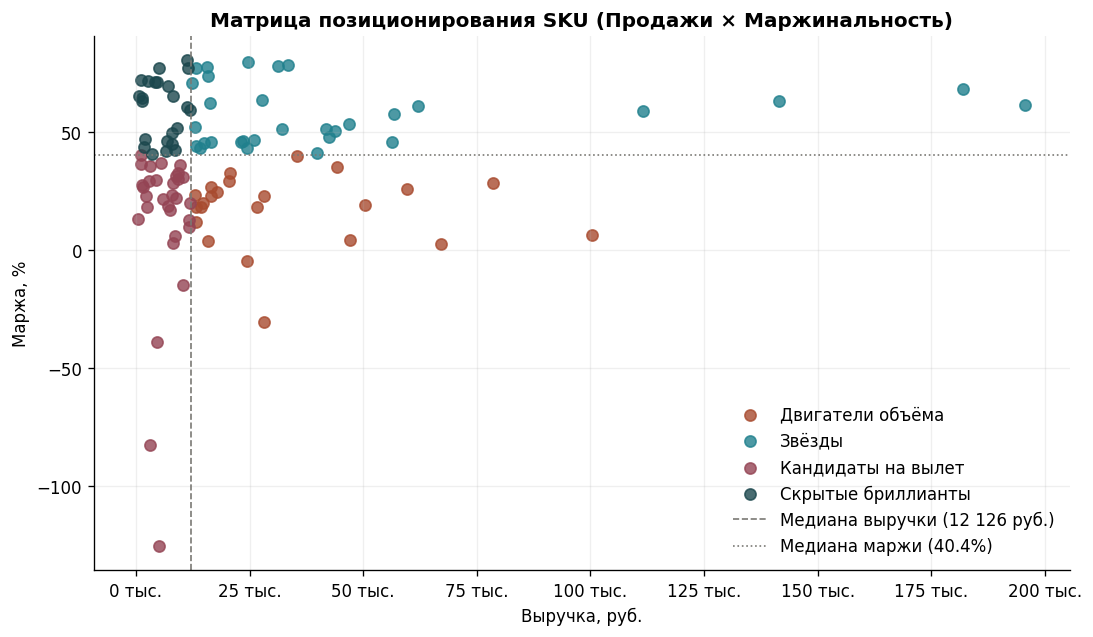

Распределение ассортимента по квадрантам:


,count
Квадрант,
Звёзды,31
Кандидаты на вылет,31
Двигатели объёма,23
Скрытые бриллианты,23


In [8]:
active_sku = mart_summary[mart_summary['Выручка, руб.'] > 0]
rev_med = active_sku['Выручка, руб.'].median()
margin_med = active_sku['Маржа, %'].median()

# График 7: Точечная матрица позиционирования
fig, ax = plt.subplots(figsize=(9, 5.2), layout='constrained')
colors = {'Звёзды': PALETTE[0], 'Двигатели объёма': PALETTE[1], 'Скрытые бриллианты': PALETTE[2], 'Кандидаты на вылет': PALETTE[3]}

for q, g in active_sku.groupby('Квадрант'):
    ax.scatter(g['Выручка, руб.'], g['Маржа, %'], s=45, alpha=0.8, label=q, color=colors.get(q, '#666'))

ax.axvline(rev_med, color='#7A7974', lw=1, ls='--', label=f'Медиана выручки ({rub(rev_med)} руб.)')
ax.axhline(margin_med, color='#7A7974', lw=1, ls=':', label=f'Медиана маржи ({margin_med:.1f}%)')
ax.set_title('Матрица позиционирования SKU (Продажи × Маржинальность)')
ax.set_xlabel('Выручка, руб.')
ax.set_ylabel('Маржа, %')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x/1000:.0f} тыс.'))
ax.legend(frameon=False)
ax.grid(alpha=0.2)
plt.show()

print("Распределение ассортимента по квадрантам:")
display(active_sku['Квадрант'].value_counts().to_frame())

### 8. Приоритизированный реестр решений (Топ рекомендаций)

In [9]:
# Выводим верхние строки таблицы решений по приоритетам 1-3
top_actions = recommendations[['Приоритет', 'SKU', 'Наименование', 'Выручка, руб.', 'Маржа, %', 'Проблема', 'Что делать', 'Ожидаемый эффект']].copy()
show(top_actions, 15)

,Приоритет,SKU,Наименование,"Выручка, руб.","Маржа, %",Проблема,Что делать,Ожидаемый эффект
0,1,бутылка_650,Бутылка 650,"100 253,0","6,4",Высокий оборот при маржинальности ниже целевой,Пересмотр ценообразования и структуры скидок,Повышение операционной рентабельности без потери объема продаж
1,1,ф_донор_XL,Футболка Донор крови XL,"78 470,0","28,6",Высокий оборот при маржинальности ниже целевой,Пересмотр ценообразования и структуры скидок,Повышение операционной рентабельности без потери объема продаж
2,1,ф_донор_L,Футболка Донор крови L,"67 132,0","2,6",Высокий оборот при маржинальности ниже целевой,Пересмотр ценообразования и структуры скидок,Повышение операционной рентабельности без потери объема продаж
3,1,вымпел,Вымпел,"59 610,0","25,9",Высокий оборот при маржинальности ниже целевой,Пересмотр ценообразования и структуры скидок,Повышение операционной рентабельности без потери объема продаж
4,1,термо_красный,термо_красный,"50 415,0","19,0",Высокий оборот при маржинальности ниже целевой,Пересмотр ценообразования и структуры скидок,Повышение операционной рентабельности без потери объема продаж
5,1,ф_донор_M,Футболка Донор крови M,"47 154,0","4,3",Высокий оборот при маржинальности ниже целевой,Пересмотр ценообразования и структуры скидок,Повышение операционной рентабельности без потери объема продаж
6,1,шапка,Шапка,"44 198,0","35,2",Высокий оборот при маржинальности ниже целевой,Пересмотр ценообразования и структуры скидок,Повышение операционной рентабельности без потери объема продаж
7,1,ремувка,Брелок для ключей автомобиля ремувка,"35 424,0","39,8",Высокий оборот при маржинальности ниже целевой,Пересмотр ценообразования и структуры скидок,Повышение операционной рентабельности без потери объема продаж
8,1,шоппер_красный,Шоппер красный,"28 191,0","-30,4",Высокий оборот при маржинальности ниже целевой,Пересмотр ценообразования и структуры скидок,Повышение операционной рентабельности без потери объема продаж
9,1,бафф_красный,Бафф зимний,"28 101,0","22,9",Высокий оборот при маржинальности ниже целевой,Пересмотр ценообразования и структуры скидок,Повышение операционной рентабельности без потери объема продаж


### 9. Итоговые выводы и аналитические инсайты

1. **Ключевой канал генерации прибыли:** Яндекс Маркет выступает ядром оборота (маржа 42.3% на сопоставимом периоде против 38.0% у Ozon при вдвое большей выручке). Приоритет инвестиций в масштабирование должен быть направлен в первую очередь на Маркет.
2. **Контроль ценообразования Ozon:** Скидки на Ozon субсидируются баллами площадки, поэтому анализ требует мониторинга обеих цен ($P_{buyer}$ и $P_{seller}$), а не номинальной «текущей цены».
3. **Ликвидация неликвидов:** Анализ кейса термостаканов подтвердил риски запоздалой распродажи ниже себестоимости. Товары с остатком без продаж требуют оперативной переоценки и прекращения дозакупок до заморозки оборотного капитала.
4. **Узкое горлышко воронки:** На Яндекс Маркете основная потеря трафика происходит на этапе «показ → корзина» (конверсия 0.5%). Для роста продаж приоритетна работа с главным фото и рейтингом карточек, а не накачка нецелевых показов.